In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, time, glob, math, gc, shutil, torch, timm
import pandas as pd, numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, ConcatDataset, WeightedRandomSampler
from torchvision.io import read_image, ImageReadMode
from torch.amp import autocast, GradScaler
from sklearn.metrics import roc_auc_score, f1_score
torch.backends.cudnn.benchmark = True

DRIVE_ROOT = '/content/drive/MyDrive/ecg_v3'
W, H     = 704, 512
CACHE    = f'/content/cache_{W}x{H}'
SUPER    = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
CKPT_DIR = f'{DRIVE_ROOT}/checkpoints'
DEVICE, BS = 'cuda', 16
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE: switch runtime to T4 GPU')
assert os.path.exists(f'{DRIVE_ROOT}/cache_{W}x{H}.tar'), 'ecg_v3 not found: add the shortcut to My Drive first'
print('checkpoints on Drive:', sorted(os.listdir(CKPT_DIR)))

# ---- unpack cached images ----
t = time.time()
if not os.path.exists(CACHE):
    !tar -xf "{DRIVE_ROOT}/cache_{W}x{H}.tar" -C /content
labels   = pd.read_csv(f'{DRIVE_ROOT}/labels/labels_genecg.csv', index_col='ecg_id')
subset_B = pd.read_csv(f'{DRIVE_ROOT}/labels/subset_B.csv', index_col='ecg_id')
nA, nB = len(glob.glob(f'{CACHE}/A/*/*.jpg')), len(glob.glob(f'{CACHE}/B/*/*.jpg'))
print(f'unpacked in {time.time() - t:.0f} s | A {nA}/{len(labels)} | B {nB}/{len(subset_B)}',
      '| CACHE OK' if (nA, nB) == (len(labels), len(subset_B)) else '| CACHE INCOMPLETE: tell me')

# ---- splits: official PTB-XL patient-level folds ----
lab  = labels[labels.n_super > 0]
labB = lab.loc[lab.index.intersection(subset_B.index)]
def split(df):
    return {'train': df[df.strat_fold <= 8], 'val': df[df.strat_fold == 9], 'test': df[df.strat_fold == 10]}
SPL = {'A': split(lab), 'B': split(labB)}

class ECGSet(Dataset):
    def __init__(self, df, sub):
        self.paths = [f'{CACHE}/{sub}/{r[:-4]}.jpg' for r in df.rel_path]
        self.y = torch.tensor(df[SUPER].values, dtype=torch.float32)
        self.ids = df.index.values
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return read_image(self.paths[i], ImageReadMode.RGB), self.y[i]

def make_loader(ds, train):
    kw = dict(batch_size=BS, num_workers=2, pin_memory=True, persistent_workers=True, prefetch_factor=4)
    if train and hasattr(ds, 'sample_weights'):
        sampler = WeightedRandomSampler(ds.sample_weights, num_samples=ds.epoch_size, replacement=True)
        return DataLoader(ds, sampler=sampler, drop_last=True, **kw)
    return DataLoader(ds, shuffle=train, drop_last=train, **kw)

# ---- GPU augmentation (no flips) ----
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def _blur(x, sigma=1.0, k=5):
    t = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    g = torch.exp(-t**2 / (2 * sigma**2)); g = g / g.sum()
    x = F.conv2d(F.pad(x, (k//2, k//2, 0, 0), mode='replicate'), g.view(1, 1, 1, k).repeat(3, 1, 1, 1), groups=3)
    x = F.conv2d(F.pad(x, (0, 0, k//2, k//2), mode='replicate'), g.view(1, 1, k, 1).repeat(3, 1, 1, 1), groups=3)
    return x

def gpu_augment(x, max_rot=3.0, max_scale=0.08, max_shift=0.04):
    B, dev = x.shape[0], x.device
    u = lambda: torch.rand(B, device=dev) * 2 - 1
    ang = u() * math.radians(max_rot)
    sc = 1 + u() * max_scale
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c, -s * H / W, u() * max_shift], 1),
                         torch.stack([s * W / H, c, u() * max_shift], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode='bilinear', padding_mode='border', align_corners=False)
    b = 1 + u().view(B, 1, 1, 1) * 0.2
    k = 1 + u().view(B, 1, 1, 1) * 0.2
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * k + m * b
    x = x + (torch.rand(B, 3, 1, 1, device=dev) * 2 - 1) * 0.04
    gmask = torch.rand(B, device=dev) < 0.2
    if gmask.any():
        gray = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).unsqueeze(1)
        x = torch.where(gmask.view(B, 1, 1, 1), gray.expand_as(x), x)
    bmask = torch.rand(B, device=dev) < 0.2
    if bmask.any():
        x[bmask] = _blur(x[bmask], sigma=float(torch.empty(1).uniform_(0.5, 1.2)))
    x = x + torch.randn_like(x) * 0.01
    return x.clamp_(0, 1)

def to_input(img_u8, train):
    with torch.autocast('cuda', enabled=False):
        x = img_u8.to(DEVICE, non_blocking=True).float().div_(255)
        if train:
            x = gpu_augment(x)
        x = (x - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)

# ---- models ----
ARCHS = {'convnext_tiny': 'convnext_tiny.fb_in22k_ft_in1k',
         'resnet18':      'resnet18.tv_in1k'}

def build_model(arch, pretrained=True):
    m = timm.create_model(ARCHS[arch], pretrained=pretrained, num_classes=len(SUPER),
                          drop_path_rate=0.1 if 'convnext' in arch else 0.0)
    return m.to(DEVICE).to(memory_format=torch.channels_last)

# ---- training / evaluation ----
@torch.no_grad()
def predict(model, ds):
    model.eval()
    dl = DataLoader(ds, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
    out = []
    for xb, _ in dl:
        with autocast('cuda', dtype=torch.float16):
            out.append(model(to_input(xb, False)).float().cpu())
    return torch.cat(out), ds.y

def metrics(logits, y):
    p, y = torch.sigmoid(logits).numpy(), y.numpy()
    aucs = [roc_auc_score(y[:, i], p[:, i]) for i in range(y.shape[1])]
    f1 = f1_score(y, p > 0.5, average='macro', zero_division=0)
    return float(np.mean(aucs)), aucs, float(f1)

def save_atomic(obj, path):
    tmp = '/content/_tmp.pth'
    torch.save(obj, tmp)
    shutil.copyfile(tmp, path + '.part'); os.replace(path + '.part', path)

def train_run(name, arch, train_ds, val_sets, select_on, epochs, lr, wd=0.05,
              init_from=None, patience=4, warmup_steps=500, log_every=200):
    last_p, best_p = f'{CKPT_DIR}/{name}_last.pth', f'{CKPT_DIR}/{name}_best.pth'
    model = build_model(arch, pretrained=init_from is None)
    if init_from:
        model.load_state_dict(torch.load(init_from, map_location=DEVICE, weights_only=False)['model'])
        print('initialised from', init_from)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    dl = make_loader(train_ds, train=True)
    total = epochs * len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warmup_steps) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    scaler = GradScaler()
    start, best, bad, hist = 0, -1.0, 0, []
    if os.path.exists(last_p):
        ck = torch.load(last_p, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
        start, best, bad, hist = ck['epoch'], ck['best'], ck['bad'], ck['hist']
        print(f'resumed {name}: {start} epochs done, best val AUROC {best:.4f}')
    if start >= epochs or bad >= patience:
        print(f'{name} already finished'); return pd.DataFrame(hist)
    print(f'{name}: {len(train_ds)} train images, {len(dl)} steps/epoch, epochs {start + 1}..{epochs}')

    for ep in range(start, epochs):
        model.train(); t0 = time.time(); run, n = 0.0, 0
        for i, (xb, yb) in enumerate(dl):
            x, y = to_input(xb, True), yb.to(DEVICE, non_blocking=True)
            with autocast('cuda', dtype=torch.float16):
                logits = model(x)
            loss = F.binary_cross_entropy_with_logits(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item(); n += 1
            if i % log_every == 0:
                print(f'  ep {ep + 1} step {i}/{len(dl)} loss {run / n:.4f} '
                      f'({(i + 1) * BS / (time.time() - t0):.0f} img/s)', flush=True)
        row = {'epoch': ep + 1, 'train_loss': round(run / n, 4),
               'lr': f"{opt.param_groups[0]['lr']:.2e}", 'train_min': round((time.time() - t0) / 60, 1)}
        for vn, vds in val_sets.items():
            auc, aucs, f1 = metrics(*predict(model, vds))
            row[f'{vn}_auc'], row[f'{vn}_f1'] = round(auc, 4), round(f1, 4)
            row.update({f'{vn}_{c}': round(a, 3) for c, a in zip(SUPER, aucs)})
        score = float(np.mean([row[f'{v}_auc'] for v in select_on]))
        if score > best:
            best, bad = score, 0
            save_atomic({'model': model.state_dict(), 'arch': arch, 'timm_name': ARCHS[arch],
                         'classes': SUPER, 'input_wh': (W, H), 'epoch': ep + 1, 'val_auc': score}, best_p)
            row['saved_best'] = True
        else:
            bad += 1
        hist.append(row)
        save_atomic({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                     'scaler': scaler.state_dict(), 'epoch': ep + 1, 'best': best, 'bad': bad, 'hist': hist}, last_p)
        pd.DataFrame(hist).to_csv(f'{CKPT_DIR}/{name}_history.csv', index=False)
        print(' | '.join(f'{k} {v}' for k, v in row.items() if not any(k.endswith('_' + c) for c in SUPER)), flush=True)
        if bad >= patience:
            print(f'early stop: no improvement for {patience} epochs'); break
    print(f'{name} done. best val AUROC {best:.4f} -> {best_p}')
    return pd.DataFrame(hist)

print('setup done')

Mounted at /content/drive
GPU: Tesla T4
checkpoints on Drive: ['convnext_s1_A_best.pth', 'convnext_s1_A_history.csv', 'convnext_s1_A_last.pth', 'convnext_s2_AB_best.pth', 'convnext_s2_AB_history.csv', 'convnext_s2_AB_last.pth']
unpacked in 88 s | A 21799/21799 | B 7378/7378 | CACHE OK
setup done


In [2]:
dsB, dsA = ECGSet(SPL['B']['train'], 'B'), ECGSet(SPL['A']['train'], 'A')
mix = ConcatDataset([dsB, dsA])
mix.sample_weights = torch.cat([torch.full((len(dsB),), 0.5 / len(dsB)),
                                torch.full((len(dsA),), 0.5 / len(dsA))]).double()
mix.epoch_size = 2 * len(dsB)

hist_s2 = train_run('convnext_s2_AB', 'convnext_tiny', mix,
                    {'A_val': ECGSet(SPL['A']['val'], 'A'), 'B_val': ECGSet(SPL['B']['val'], 'B')},
                    select_on=['A_val', 'B_val'], epochs=12, lr=5e-5,
                    init_from=f'{CKPT_DIR}/convnext_s1_A_best.pth',
                    warmup_steps=100, log_every=100)

initialised from /content/drive/MyDrive/ecg_v3/checkpoints/convnext_s1_A_best.pth
resumed convnext_s2_AB: 6 epochs done, best val AUROC 0.9271
convnext_s2_AB: 20019 train images, 366 steps/epoch, epochs 7..12
  ep 7 step 0/366 loss 0.2033 (1 img/s)
  ep 7 step 100/366 loss 0.2307 (20 img/s)
  ep 7 step 200/366 loss 0.2228 (23 img/s)
  ep 7 step 300/366 loss 0.2243 (25 img/s)
epoch 7 | train_loss 0.224 | lr 1.85e-05 | train_min 3.8 | A_val_auc 0.9343 | A_val_f1 0.7512 | B_val_auc 0.9198 | B_val_f1 0.7225
  ep 8 step 0/366 loss 0.0996 (21 img/s)
  ep 8 step 100/366 loss 0.2147 (27 img/s)
  ep 8 step 200/366 loss 0.2126 (28 img/s)
  ep 8 step 300/366 loss 0.2128 (28 img/s)
epoch 8 | train_loss 0.2123 | lr 1.25e-05 | train_min 3.5 | A_val_auc 0.935 | A_val_f1 0.7516 | B_val_auc 0.9203 | B_val_f1 0.7201 | saved_best True
  ep 9 step 0/366 loss 0.2912 (22 img/s)
  ep 9 step 100/366 loss 0.2301 (27 img/s)
  ep 9 step 200/366 loss 0.2232 (28 img/s)
  ep 9 step 300/366 loss 0.2184 (28 img/s)
ep

In [3]:
import json
RES = f'{DRIVE_ROOT}/results'; os.makedirs(RES, exist_ok=True)
SETS = {f'{s}_{sp}': ECGSet(SPL[s][sp], s) for s in ['A', 'B'] for sp in ['val', 'test']}

def get_logits(name):
    # run the best checkpoint once on val + test, cache logits on Drive
    p = f'{RES}/{name}_logits.pt'
    if os.path.exists(p): return torch.load(p)
    ck = torch.load(f'{CKPT_DIR}/{name}_best.pth', map_location=DEVICE, weights_only=False)
    m = build_model(ck['arch'], pretrained=False); m.load_state_dict(ck['model'])
    out = {k: predict(m, ds) for k, ds in SETS.items()}
    torch.save(out, p); del m; gc.collect(); torch.cuda.empty_cache()
    return out

def fit_temperature(logits, y):
    logT = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(logits / logT.exp(), y)
        loss.backward(); return loss
    opt.step(closure)
    return float(logT.detach().exp())

def ece(p, y, bins=15):
    out = []
    for c in range(p.shape[1]):
        idx = np.minimum((p[:, c] * bins).astype(int), bins - 1)
        out.append(sum((idx == b).mean() * abs(p[idx == b, c].mean() - y[idx == b, c].mean())
                       for b in range(bins) if (idx == b).any()))
    return float(np.mean(out))

def best_thresholds(p, y):
    ths = np.linspace(0.05, 0.95, 91)
    return np.array([ths[np.argmax([f1_score(y[:, c], p[:, c] >= t, zero_division=0) for t in ths])]
                     for c in range(p.shape[1])])

def boot_ci(p, y, n=1000, seed=0):
    rng, N, vals = np.random.default_rng(seed), len(y), []
    for _ in range(n):
        i = rng.integers(0, N, N)
        if (y[i].sum(0) == 0).any(): continue
        vals.append(np.mean([roc_auc_score(y[i, c], p[i, c]) for c in range(y.shape[1])]))
    return np.percentile(vals, [2.5, 97.5])

def sens_spec(p, y, th):
    pred = p >= th
    return (pred & (y == 1)).sum(0) / (y == 1).sum(0), (~pred & (y == 0)).sum(0) / (y == 0).sum(0)

rows, calib = [], {}
for name in ['convnext_s1_A', 'convnext_s2_AB']:
    L = get_logits(name)
    # temperature + per-class thresholds are fitted on VALIDATION only (A_val + B_val together)
    lv = torch.cat([L['A_val'][0], L['B_val'][0]]); yv = torch.cat([L['A_val'][1], L['B_val'][1]])
    T = fit_temperature(lv, yv)
    th = best_thresholds(torch.sigmoid(lv / T).numpy(), yv.numpy())
    calib[name] = {'temperature': T, 'thresholds': dict(zip(SUPER, th.round(2).tolist())), 'classes': SUPER}
    for s in ['A_test', 'B_test']:
        lg, y = L[s][0], L[s][1].numpy()
        p_raw, p = torch.sigmoid(lg).numpy(), torch.sigmoid(lg / T).numpy()
        auc, aucs, f1_05 = metrics(lg, L[s][1])
        lo, hi = boot_ci(p, y)
        se, sp = sens_spec(p, y, th)
        rows.append({'model': name, 'test_set': s, 'n': len(y),
                     'macro_AUROC': round(auc, 4), '95%CI': f'{lo:.3f}-{hi:.3f}',
                     'F1@0.5': round(f1_05, 4),
                     'F1@tuned': round(f1_score(y, p >= th, average='macro', zero_division=0), 4),
                     'sens': round(se.mean(), 3), 'spec': round(sp.mean(), 3),
                     'ECE_raw': round(ece(p_raw, y), 4), 'ECE_cal': round(ece(p, y), 4),
                     **{c: round(a, 3) for c, a in zip(SUPER, aucs)}})

res = pd.DataFrame(rows)
res.to_csv(f'{RES}/test_results_convnext.csv', index=False)
json.dump(calib, open(f'{RES}/calibration_convnext.json', 'w'), indent=2)
pd.set_option('display.width', 250)
print(res.to_string(index=False))
print('\ncalibration (fitted on val):', json.dumps(calib['convnext_s2_AB'], indent=1))

         model test_set    n  macro_AUROC       95%CI  F1@0.5  F1@tuned  sens  spec  ECE_raw  ECE_cal  NORM    MI  STTC    CD   HYP
 convnext_s1_A   A_test 2158       0.9324 0.926-0.939  0.7524    0.7429 0.799 0.877   0.0288   0.0195 0.952 0.936 0.939 0.931 0.905
 convnext_s1_A   B_test 2156       0.8450 0.834-0.855  0.5228    0.6160 0.642 0.857   0.0947   0.1001 0.888 0.851 0.878 0.822 0.786
convnext_s2_AB   A_test 2158       0.9310 0.924-0.938  0.7513    0.7553 0.781 0.909   0.0348   0.0236 0.950 0.934 0.937 0.929 0.906
convnext_s2_AB   B_test 2156       0.9173 0.909-0.925  0.7290    0.7326 0.760 0.900   0.0466   0.0278 0.939 0.908 0.930 0.910 0.899

calibration (fitted on val): {
 "temperature": 1.3793549537658691,
 "thresholds": {
  "NORM": 0.48,
  "MI": 0.47,
  "STTC": 0.37,
  "CD": 0.42,
  "HYP": 0.27
 },
 "classes": [
  "NORM",
  "MI",
  "STTC",
  "CD",
  "HYP"
 ]
}


In [4]:
# ---- stage 1: ResNet18 on clean A ----
VAL = {'A_val': ECGSet(SPL['A']['val'], 'A'), 'B_val': ECGSet(SPL['B']['val'], 'B')}
train_run('resnet18_s1_A', 'resnet18', ECGSet(SPL['A']['train'], 'A'), VAL,
          select_on=['A_val'], epochs=10, lr=3e-4, log_every=400)

# ---- stage 2: ResNet18 on 50/50 photos + clean ----
dsB, dsA = ECGSet(SPL['B']['train'], 'B'), ECGSet(SPL['A']['train'], 'A')
mix = ConcatDataset([dsB, dsA])
mix.sample_weights = torch.cat([torch.full((len(dsB),), 0.5 / len(dsB)),
                                torch.full((len(dsA),), 0.5 / len(dsA))]).double()
mix.epoch_size = 2 * len(dsB)
train_run('resnet18_s2_AB', 'resnet18', mix, VAL,
          select_on=['A_val', 'B_val'], epochs=12, lr=1.5e-4,
          init_from=f'{CKPT_DIR}/resnet18_s1_A_best.pth', warmup_steps=100, log_every=400)

# ---- same test evaluation as R3, for all four models ----
rows, calib = [], {}
for name in ['convnext_s1_A', 'convnext_s2_AB', 'resnet18_s1_A', 'resnet18_s2_AB']:
    L = get_logits(name)
    lv = torch.cat([L['A_val'][0], L['B_val'][0]]); yv = torch.cat([L['A_val'][1], L['B_val'][1]])
    T = fit_temperature(lv, yv)
    th = best_thresholds(torch.sigmoid(lv / T).numpy(), yv.numpy())
    calib[name] = {'temperature': T, 'thresholds': dict(zip(SUPER, th.round(2).tolist())), 'classes': SUPER}
    for s in ['A_test', 'B_test']:
        lg, y = L[s][0], L[s][1].numpy()
        p_raw, p = torch.sigmoid(lg).numpy(), torch.sigmoid(lg / T).numpy()
        auc, aucs, f1_05 = metrics(lg, L[s][1])
        lo, hi = boot_ci(p, y)
        se, sp = sens_spec(p, y, th)
        rows.append({'model': name, 'test_set': s, 'n': len(y),
                     'macro_AUROC': round(auc, 4), '95%CI': f'{lo:.3f}-{hi:.3f}',
                     'F1@0.5': round(f1_05, 4),
                     'F1@tuned': round(f1_score(y, p >= th, average='macro', zero_division=0), 4),
                     'sens': round(se.mean(), 3), 'spec': round(sp.mean(), 3),
                     'ECE_raw': round(ece(p_raw, y), 4), 'ECE_cal': round(ece(p, y), 4),
                     **{c: round(a, 3) for c, a in zip(SUPER, aucs)}})
res = pd.DataFrame(rows)
res.to_csv(f'{RES}/test_results_all.csv', index=False)
json.dump(calib, open(f'{RES}/calibration_all.json', 'w'), indent=2)
print(res.to_string(index=False))


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet18_s1_A: 17084 train images, 1067 steps/epoch, epochs 1..10
  ep 1 step 0/1067 loss 0.6956 (4 img/s)
  ep 1 step 400/1067 loss 0.4539 (102 img/s)
  ep 1 step 800/1067 loss 0.4025 (107 img/s)
epoch 1 | train_loss 0.3808 | lr 2.93e-04 | train_min 2.6 | A_val_auc 0.8932 | A_val_f1 0.6056 | B_val_auc 0.8022 | B_val_f1 0.2725 | saved_best True
  ep 2 step 0/1067 loss 0.3452 (49 img/s)
  ep 2 step 400/1067 loss 0.3085 (111 img/s)
  ep 2 step 800/1067 loss 0.3010 (111 img/s)
epoch 2 | train_loss 0.3032 | lr 2.71e-04 | train_min 2.5 | A_val_auc 0.9193 | A_val_f1 0.6572 | B_val_auc 0.7911 | B_val_f1 0.3396 | saved_best True
  ep 3 step 0/1067 loss 0.3521 (49 img/s)
  ep 3 step 400/1067 loss 0.2881 (110 img/s)
  ep 3 step 800/1067 loss 0.2864 (111 img/s)
epoch 3 | train_loss 0.2832 | lr 2.38e-04 | train_min 2.6 | A_val_auc 0.9236 | A_val_f1 0.7104 | B_val_auc 0.7985 | B_val_f1 0.4012 | saved_best True
  ep 4 step 0/1067 loss 0.2781 (55 img/s)
  ep 4 step 400/1067 loss 0.2706 (110 img/s)
  

In [5]:
def macro_auc(p, y):
    return float(np.mean([roc_auc_score(y[:, c], p[:, c]) for c in range(y.shape[1])]))

def paired_boot(pa, pb, y, groups, n=1000, seed=0):
    # resample PATIENTS (not ECGs), same resample for both models -> CI and p-value of the difference
    rng = np.random.default_rng(seed)
    _, inv = np.unique(groups, return_inverse=True)
    order = np.argsort(inv, kind='stable'); counts = np.bincount(inv)
    starts = np.concatenate([[0], np.cumsum(counts)[:-1]])
    G, d = len(counts), []
    for _ in range(n):
        pick = rng.integers(0, G, G)
        i = order[np.concatenate([np.arange(starts[g], starts[g] + counts[g]) for g in pick])]
        if (y[i].sum(0) == 0).any(): continue
        d.append(macro_auc(pa[i], y[i]) - macro_auc(pb[i], y[i]))
    d = np.array(d)
    p = max(2 * min((d <= 0).mean(), (d >= 0).mean()), 1 / len(d))
    return macro_auc(pa, y) - macro_auc(pb, y), np.percentile(d, [2.5, 97.5]), p

cal = json.load(open(f'{RES}/calibration_all.json'))
P = {}   # calibrated test probabilities per model
for name in ['convnext_s1_A', 'convnext_s2_AB', 'resnet18_s1_A', 'resnet18_s2_AB']:
    L = torch.load(f'{RES}/{name}_logits.pt')
    T = cal[name]['temperature']
    P[name] = {s: torch.sigmoid(L[s][0] / T).numpy() for s in ['A_test', 'B_test']}
Y = {s: L[s][1].numpy() for s in ['A_test', 'B_test']}
GRP = {'A_test': SPL['A']['test'].patient_id.values, 'B_test': SPL['B']['test'].patient_id.values}
P['ensemble_s2'] = {s: (P['convnext_s2_AB'][s] + P['resnet18_s2_AB'][s]) / 2 for s in ['A_test', 'B_test']}

tests = [('convnext_s2_AB', 'resnet18_s2_AB', 'A_test', 'architecture, after 2-stage'),
         ('convnext_s2_AB', 'resnet18_s2_AB', 'B_test', 'architecture, after 2-stage'),
         ('convnext_s1_A',  'resnet18_s1_A',  'B_test', 'architecture, photos never seen'),
         ('convnext_s2_AB', 'convnext_s1_A',  'B_test', 'stage-2 effect, ConvNeXt'),
         ('resnet18_s2_AB', 'resnet18_s1_A',  'B_test', 'stage-2 effect, ResNet18'),
         ('ensemble_s2',    'convnext_s2_AB', 'A_test', 'ensemble vs ConvNeXt'),
         ('ensemble_s2',    'convnext_s2_AB', 'B_test', 'ensemble vs ConvNeXt')]
out = []
for a, b, s, what in tests:
    t = time.time()
    dlt, (lo, hi), p = paired_boot(P[a][s], P[b][s], Y[s], GRP[s])
    out.append({'comparison': what, 'A': a, 'B': b, 'test_set': s,
                'AUROC_A': round(macro_auc(P[a][s], Y[s]), 4), 'AUROC_B': round(macro_auc(P[b][s], Y[s]), 4),
                'delta': round(dlt, 4), '95%CI': f'{lo:+.4f} to {hi:+.4f}', 'p': round(p, 4)})
    print(f'done: {what} on {s} ({time.time() - t:.0f}s)', flush=True)
cmp = pd.DataFrame(out)
cmp.to_csv(f'{RES}/paired_comparisons.csv', index=False)
print(cmp.to_string(index=False))

done: architecture, after 2-stage on A_test (25s)
done: architecture, after 2-stage on B_test (22s)
done: architecture, photos never seen on B_test (22s)
done: stage-2 effect, ConvNeXt on B_test (23s)
done: stage-2 effect, ResNet18 on B_test (22s)
done: ensemble vs ConvNeXt on A_test (22s)
done: ensemble vs ConvNeXt on B_test (24s)
                     comparison              A              B test_set  AUROC_A  AUROC_B  delta              95%CI     p
    architecture, after 2-stage convnext_s2_AB resnet18_s2_AB   A_test   0.9310   0.9296 0.0014 -0.0017 to +0.0044 0.348
    architecture, after 2-stage convnext_s2_AB resnet18_s2_AB   B_test   0.9173   0.9106 0.0066 +0.0023 to +0.0115 0.004
architecture, photos never seen  convnext_s1_A  resnet18_s1_A   B_test   0.8450   0.7547 0.0903 +0.0790 to +0.1018 0.001
       stage-2 effect, ConvNeXt convnext_s2_AB  convnext_s1_A   B_test   0.9173   0.8450 0.0723 +0.0634 to +0.0807 0.001
       stage-2 effect, ResNet18 resnet18_s2_AB  resnet18_s1_A

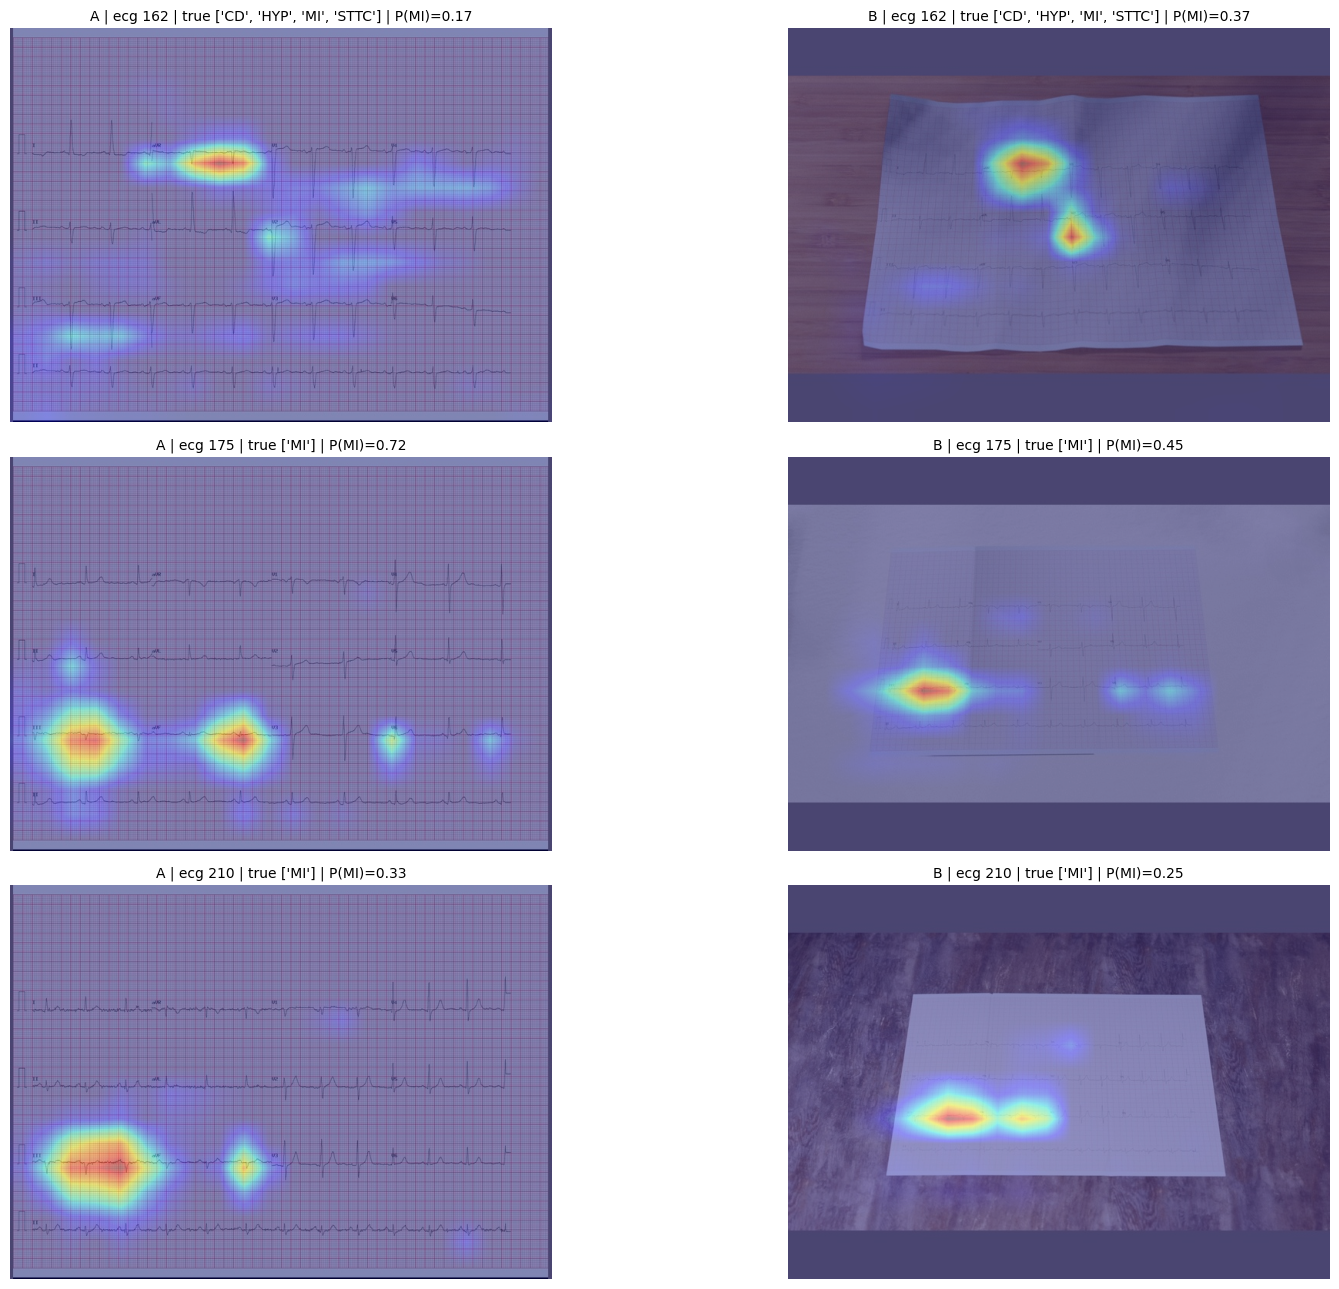

-rw------- 1 root root 54M Oct 31 08:26 /content/drive/MyDrive/ecg_v3/results/ecg_convnext_v3_deploy.pth


In [6]:
# ---- load final model + its calibration ----
ck = torch.load(f'{CKPT_DIR}/convnext_s2_AB_best.pth', map_location=DEVICE, weights_only=False)
model = build_model('convnext_tiny', pretrained=False); model.load_state_dict(ck['model']); model.eval()
T = cal['convnext_s2_AB']['temperature']

# ---- Grad-CAM on the last ConvNeXt stage ----
acts = {}
hook = model.stages[-1].register_forward_hook(lambda m, i, o: acts.__setitem__('a', o))
def gradcam(img_u8, cls):
    out = model(to_input(img_u8[None], False))
    a = acts['a']
    g = torch.autograd.grad(out[0, cls], a)[0]
    cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(H, W), mode='bilinear', align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), torch.sigmoid(out[0].detach() / T).cpu().numpy()

# the SAME ECG rendered clean (A) and photographed (B): first 3 MI-positive ECGs of the test fold
MI = SUPER.index('MI')
ids = SPL['B']['test'][SPL['B']['test'].MI == 1].index[:3]
fig, ax = plt.subplots(3, 2, figsize=(18, 13))
for r, eid in enumerate(ids):
    for c, sub in enumerate(['A', 'B']):
        row = SPL[sub]['test'].loc[eid]
        img = read_image(f'{CACHE}/{sub}/{row.rel_path[:-4]}.jpg', ImageReadMode.RGB)
        cam, prob = gradcam(img, MI)
        ax[r, c].imshow(img.permute(1, 2, 0)); ax[r, c].imshow(cam, cmap='jet', alpha=0.4)
        ax[r, c].set_title(f'{sub} | ecg {eid} | true {row.superclasses} | P(MI)={prob[MI]:.2f}', fontsize=10)
        ax[r, c].axis('off')
hook.remove()
plt.tight_layout(); plt.savefig(f'{RES}/gradcam_mi.png', dpi=110); plt.show()

# ---- export: one small file with everything the inference code needs ----
deploy = {
    'model_fp16': {k: v.half() for k, v in ck['model'].items()},
    'timm_name': ARCHS['convnext_tiny'], 'classes': SUPER,
    'input_wh': (W, H), 'letterbox_fill': (124, 116, 104),
    'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225],
    'temperature': T, 'thresholds': cal['convnext_s2_AB']['thresholds'],
    'test_macro_auroc': {'clean_A': 0.9310, 'photo_B': 0.9173},
    'trained_on': 'GenECG (PTB-XL images) folds 1-8, 2-stage clean->photo, best epoch on fold 9',
}
torch.save(deploy, f'{RES}/ecg_convnext_v3_deploy.pth')
!ls -lh "{RES}/ecg_convnext_v3_deploy.pth"

                                                                   scp_codes
ecg_id                                                                      
162     {'ASMI': 50.0, 'LAFB': 100.0, 'LVH': 50.0, 'ISC_': 100.0, 'SR': 0.0}
175                                   {'IMI': 15.0, 'ABQRS': 0.0, 'SR': 0.0}
210                                                 {'IMI': 80.0, 'SR': 0.0} 

{'abnormal': 233, 'normal': 142, 'history_mi': 86, 'mi': 30} | files found: 491 / 491
image sizes: [((2213, 1572), 491)]
full_page done
grid_crop done

AUROC (95% CI) on real Mendeley printouts:
                                task   n  n_pos           full_page           grid_crop
  MI + history-MI vs normal  [P(MI)] 258    116 0.947 (0.919-0.972) 0.939 (0.909-0.965)
  acute MI vs normal         [P(MI)] 172     30 0.932 (0.892-0.966) 0.914 (0.865-0.955)
  MI + history-MI vs all     [P(MI)] 491    116 0.906 (0.879-0.931) 0.901 (0.873-0.927)
normal vs all abnormal     [P(NORM)] 491    142 0.843 (0.803-0.878

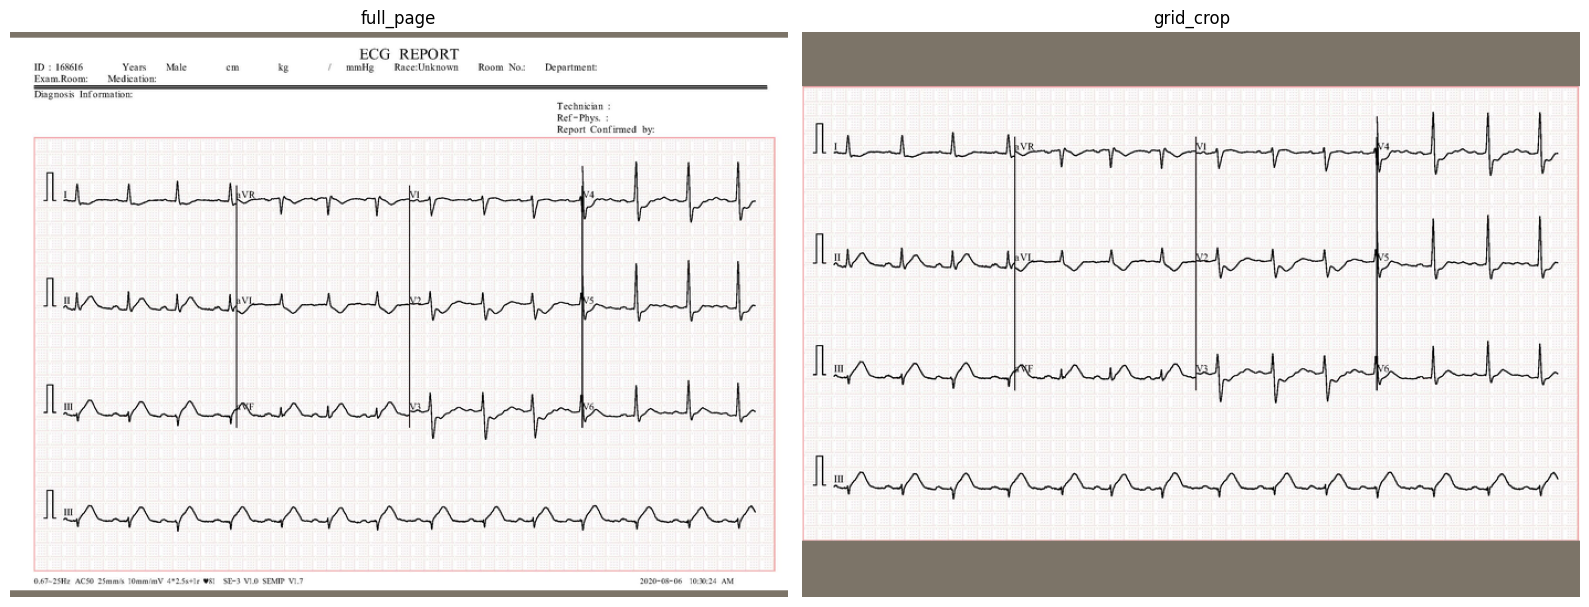

In [10]:
import collections
from PIL import Image

# ---- 1. what were the 3 Grad-CAM ECGs diagnosed with? (PTB-XL statement codes) ----
db = pd.read_csv(f'{DRIVE_ROOT}/labels/ptbxl_database.csv', index_col='ecg_id')
print(db.loc[[162, 175, 210], ['scp_codes']].to_string(), '\n')

# ---- 2. unpack Mendeley (Khan & Hussain) and keep only the 491 unique images ----
EXT, MEND = f'{DRIVE_ROOT}/external', '/content/mendeley'
if not os.path.exists(MEND):
    !unzip -q "{EXT}/gwbz3fsgp8-2.zip" -d {MEND}
u = pd.read_csv(f'{EXT}/unique_images.csv')
u['local'] = MEND + '/' + u.path.str.split('/', n=3).str[3]
print(u.cls.value_counts().to_dict(), '| files found:', u.local.map(os.path.exists).sum(), '/', len(u))
print('image sizes:', collections.Counter(Image.open(p).size for p in u.local).most_common(3))

def letterbox_pil(im):
    im = im.convert('RGB')
    s = min(W / im.width, H / im.height); nw, nh = round(im.width * s), round(im.height * s)
    canvas = Image.new('RGB', (W, H), (124, 116, 104))
    canvas.paste(im.resize((nw, nh), Image.LANCZOS), ((W - nw) // 2, (H - nh) // 2))
    return torch.from_numpy(np.asarray(canvas).copy()).permute(2, 0, 1)

VARIANTS = {
    'full_page': lambda im: im,
    'grid_crop': lambda im: im.crop((round(.03 * im.width), round(.18 * im.height),
                                     round(.985 * im.width), round(.965 * im.height))),
}

# ---- 3. run the final model (stage 2 ConvNeXt, calibrated) ----
ck = torch.load(f'{CKPT_DIR}/convnext_s2_AB_best.pth', map_location=DEVICE, weights_only=False)
model = build_model('convnext_tiny', pretrained=False); model.load_state_dict(ck['model']); model.eval()
T = cal['convnext_s2_AB']['temperature']
PM = {}
for v, fn in VARIANTS.items():
    out = []
    for i in range(0, len(u), 32):
        xb = torch.stack([letterbox_pil(fn(Image.open(p))) for p in u.local[i:i + 32]])
        with torch.no_grad(), autocast('cuda', dtype=torch.float16):
            out.append(model(to_input(xb, False)).float().cpu())
    PM[v] = torch.sigmoid(torch.cat(out) / T).numpy()
    print(v, 'done')

# ---- 4. metrics ----
def auc_ci(y, s, n=2000, seed=0):
    rng, vals = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i): vals.append(roc_auc_score(y[i], s[i]))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return f'{roc_auc_score(y, s):.3f} ({lo:.3f}-{hi:.3f})'

c = u.cls.values
tasks = {
    'MI + history-MI vs normal  [P(MI)]':   (np.isin(c, ['mi', 'history_mi', 'normal']), np.isin(c, ['mi', 'history_mi']), 'MI'),
    'acute MI vs normal         [P(MI)]':   (np.isin(c, ['mi', 'normal']), c == 'mi', 'MI'),
    'MI + history-MI vs all     [P(MI)]':   (np.ones(len(c), bool), np.isin(c, ['mi', 'history_mi']), 'MI'),
    'normal vs all abnormal     [P(NORM)]': (np.ones(len(c), bool), c == 'normal', 'NORM'),
}
rows = []
for name, (keep, pos, cls_) in tasks.items():
    rows.append({'task': name, 'n': int(keep.sum()), 'n_pos': int(pos[keep].sum()),
                 **{v: auc_ci(pos[keep].astype(int), PM[v][keep, SUPER.index(cls_)]) for v in VARIANTS}})
ext = pd.DataFrame(rows); ext.to_csv(f'{RES}/external_mendeley.csv', index=False)
print('\nAUROC (95% CI) on real Mendeley printouts:'); print(ext.to_string(index=False))
print('\nmean calibrated probability per true group (grid_crop):')
print(pd.DataFrame(PM['grid_crop'], columns=SUPER).groupby(c).mean().round(3).to_string())

# ---- 5. look at what the model sees after cropping ----
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
im0 = Image.open(u.local[0])
for a, (v, fn) in zip(ax, VARIANTS.items()):
    a.imshow(letterbox_pil(fn(im0)).permute(1, 2, 0)); a.set_title(v); a.axis('off')
plt.tight_layout(); plt.show()

In [11]:
import shutil
RES = f'{DRIVE_ROOT}/results'
DEP = f'{DRIVE_ROOT}/deploy'
os.makedirs(f'{DEP}/weights', exist_ok=True)
shutil.copy(f'{RES}/ecg_convnext_v3_deploy.pth', f'{DEP}/weights/ecg_convnext_v3_deploy.pth')
!ls -lh {DEP}/weights

total 54M
-rw------- 1 root root 54M Oct 31 08:53 ecg_convnext_v3_deploy.pth


In [12]:
%%writefile /content/drive/MyDrive/ecg_v3/deploy/ecg_inference.py
"""
ECG image inference, model v3 (ConvNeXt-Tiny, 5 PTB-XL superclasses, multi-label).

Drop-in replacement for the v1 module: same function names and the same output keys,
plus the multi-label fields used by the X-ray module (normality_score, risk tiers).

    from ecg_inference import predict_ecg
    result = predict_ecg("ecg.jpg")                 # path, raw bytes or PIL.Image
    result = predict_ecg(img_bytes, gradcam=True)   # adds a heatmap (base64 PNG)

Needs: torch, timm, pillow, numpy.
Weights: ecg_convnext_v3_deploy.pth (set ECG_V3_WEIGHTS or put it in ./weights/).
"""
import os
import io
import json
import base64
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

MODEL_VERSION = "ecg-v3-convnext-tiny"
WEIGHTS_FILENAME = "ecg_convnext_v3_deploy.pth"

CLINICAL_LABEL_MAP = {
    "NORM": "Normal ECG",
    "MI":   "Myocardial Infarction",
    "STTC": "ST/T-wave Changes",
    "CD":   "Conduction Disturbance",
    "HYP":  "Ventricular Hypertrophy",
}

CLINICAL_FINDINGS_MAP = {
    "NORM": "Normal 12-lead ECG pattern.",
    "MI":   "Pattern consistent with myocardial infarction (acute or old), e.g. pathological Q waves, "
            "ST-segment elevation or poor R-wave progression.",
    "STTC": "ST-segment / T-wave changes (e.g. ST depression, T-wave inversion) suggestive of ischaemia, "
            "strain or electrolyte effect.",
    "CD":   "Conduction disturbance pattern (e.g. bundle branch block, fascicular block, AV block).",
    "HYP":  "Voltage / morphology pattern consistent with ventricular hypertrophy.",
}

LIMITATION_NOTE = ("Model covers 5 PTB-XL diagnostic superclasses only; it does not assess rhythm "
                   "(e.g. atrial fibrillation) or distinguish acute from old MI.")

_CACHE = {"model": None, "device": None, "cfg": None, "path": None}


# ----------------------------------------------------------------------------- loading
def get_default_weights_path():
    here = os.path.dirname(os.path.abspath(__file__))
    candidates = [
        os.environ.get("ECG_V3_WEIGHTS", ""),
        os.path.join(here, "weights", WEIGHTS_FILENAME),
        os.path.join(here, WEIGHTS_FILENAME),
        WEIGHTS_FILENAME,
    ]
    for p in candidates:
        if p and os.path.exists(p):
            return p
    return candidates[1]


def load_ecg_model(model_path=None, device=None):
    """Loads the model once and keeps it in memory. Returns (model, device)."""
    import timm
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    model_path = model_path or get_default_weights_path()
    if _CACHE["model"] is not None and _CACHE["device"] == device and _CACHE["path"] == model_path:
        return _CACHE["model"], device
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"ECG v3 weights not found at: {model_path}")

    cfg = torch.load(model_path, map_location="cpu", weights_only=False)
    model = timm.create_model(cfg["timm_name"], pretrained=False, num_classes=len(cfg["classes"]))
    model.load_state_dict({k: v.float() for k, v in cfg["model_fp16"].items()})
    model.to(device).eval()
    _CACHE.update(model=model, device=device, cfg=cfg, path=model_path)
    return model, device


# ----------------------------------------------------------------------------- preprocessing
def _to_pil(image_input):
    if isinstance(image_input, Image.Image):
        return image_input.convert("RGB")
    if isinstance(image_input, (bytes, bytearray)):
        return Image.open(io.BytesIO(image_input)).convert("RGB")
    if isinstance(image_input, (str, os.PathLike)):
        return Image.open(image_input).convert("RGB")
    raise ValueError("image_input must be a file path, PIL.Image, or bytes.")


def preprocess_ecg_image(image_input, cfg):
    """Letterbox to the training size (keep aspect ratio, pad), normalise. Returns (tensor, letterboxed PIL)."""
    img = _to_pil(image_input)
    W, H = cfg["input_wh"]
    s = min(W / img.width, H / img.height)
    nw, nh = round(img.width * s), round(img.height * s)
    canvas = Image.new("RGB", (W, H), tuple(cfg["letterbox_fill"]))
    canvas.paste(img.resize((nw, nh), Image.LANCZOS), ((W - nw) // 2, (H - nh) // 2))
    x = torch.from_numpy(np.asarray(canvas, dtype=np.float32) / 255.0).permute(2, 0, 1)
    mean = torch.tensor(cfg["mean"]).view(3, 1, 1)
    std = torch.tensor(cfg["std"]).view(3, 1, 1)
    return ((x - mean) / std).unsqueeze(0), canvas


# ----------------------------------------------------------------------------- grad-cam
def _gradcam(model, x, class_idx):
    acts = {}
    h = model.stages[-1].register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))
    try:
        with torch.enable_grad():
            out = model(x)
            a = acts["a"]
            g = torch.autograd.grad(out[0, class_idx], a)[0]
    finally:
        h.remove()
    cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy()


def _overlay_png_base64(canvas, cam):
    # jet colour map without matplotlib
    heat = np.stack([np.clip(1.5 - np.abs(4 * cam - k), 0, 1) for k in (3, 2, 1)], -1) * 255
    blended = (0.6 * np.asarray(canvas, dtype=np.float32) + 0.4 * heat).astype(np.uint8)
    buf = io.BytesIO()
    Image.fromarray(blended).save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode("ascii")


# ----------------------------------------------------------------------------- main entry
def predict_ecg(image_input, model_path=None, device=None, gradcam=False):
    """
    Runs ECG image inference and returns the standardized JSON evidence packet.

    Risk tiers per condition use calibrated probabilities and per-class thresholds
    tuned on the validation fold:
      detected  : p >= threshold
      watchlist : max(0.15, threshold/2) <= p < threshold
      unlikely  : below that
    """
    model, device = load_ecg_model(model_path=model_path, device=device)
    cfg = _CACHE["cfg"]
    classes, T, th = cfg["classes"], float(cfg["temperature"]), cfg["thresholds"]

    x, canvas = preprocess_ecg_image(image_input, cfg)
    x = x.to(device).contiguous(memory_format=torch.channels_last)
    with torch.no_grad():
        logits = model(x).float().cpu()[0]
    raw = torch.sigmoid(logits).numpy()
    cal = torch.sigmoid(logits / T).numpy()

    def tier(c, p):
        if p >= th[c]:
            return "detected"
        if p >= max(0.15, th[c] / 2):
            return "watchlist"
        return "unlikely"

    entries = {}
    for i, c in enumerate(classes):
        entries[c] = {
            "label": CLINICAL_LABEL_MAP[c],
            "raw_class": c,
            "probability": round(float(raw[i]), 4),
            "calibrated_probability": round(float(cal[i]), 4),
            "threshold": th[c],
            "risk_tier": tier(c, float(cal[i])),
        }
    full_differential = sorted(entries.values(), key=lambda e: e["calibrated_probability"], reverse=True)
    disease = [e for e in full_differential if e["raw_class"] != "NORM"]
    detected = [e for e in disease if e["risk_tier"] == "detected"]
    watchlist = [e for e in disease if e["risk_tier"] == "watchlist"]
    unlikely = [e for e in disease if e["risk_tier"] == "unlikely"]
    norm = entries["NORM"]
    normality_score = norm["calibrated_probability"]
    norm_positive = normality_score >= th["NORM"]

    # ---- primary diagnosis + abstain ("refer to specialist") ----
    abstain, abstain_reason = False, None
    if detected:
        primary = detected[0]
        primary_diagnosis, primary_class = primary["label"], primary["raw_class"]
        if norm_positive:
            abstain, abstain_reason = True, "Model rates the ECG as both normal and abnormal (conflicting outputs)."
    elif watchlist:
        primary = watchlist[0]
        primary_diagnosis = f"{primary['label']} (watchlist - needs clinical correlation)"
        primary_class = primary["raw_class"]
        if not norm_positive:
            abstain, abstain_reason = True, "No condition reaches its threshold and normality is low."
    elif norm_positive:
        primary = norm
        primary_diagnosis, primary_class = norm["label"], "NORM"
    else:
        primary = norm
        primary_diagnosis, primary_class = "Indeterminate - refer to specialist", "INDETERMINATE"
        abstain, abstain_reason = True, "No class reaches its threshold, including normal."

    # ---- evidence for the debate agents ----
    positive_findings, negative_findings = [], []
    for e in detected:
        positive_findings.append(f"[DETECTED] {e['label']} ({e['calibrated_probability']:.1%}): "
                                 f"{CLINICAL_FINDINGS_MAP[e['raw_class']]}")
    for e in watchlist:
        positive_findings.append(f"[WATCHLIST] Cannot rule out {e['label']} ({e['calibrated_probability']:.1%}): "
                                 f"{CLINICAL_FINDINGS_MAP[e['raw_class']]}")
    if not positive_findings:
        positive_findings.append(CLINICAL_FINDINGS_MAP["NORM"] if norm_positive
                                 else "No specific abnormality pattern reaches its decision threshold.")
    if normality_score >= th["NORM"]:
        negative_findings.append(f"Normality score: {normality_score:.1%} - likely normal ECG.")
    elif normality_score >= 0.25:
        negative_findings.append(f"Normality score: {normality_score:.1%} - borderline, clinical correlation advised.")
    else:
        negative_findings.append(f"Normality score: {normality_score:.1%} - abnormalities likely present.")
    for e in unlikely:
        negative_findings.append(f"{e['label']} unlikely ({e['calibrated_probability']:.1%}).")
    negative_findings.append(LIMITATION_NOTE)
    if abstain:
        # agents read only the first negative finding, so the referral reason goes first
        negative_findings.insert(0, f"[REFER] Low-confidence result, specialist review advised: {abstain_reason}")

    explain = {
        "method": "Grad-CAM",
        "target_layer": "convnext_tiny.stages[3]",
        "target_class": primary_class if primary_class in classes else "NORM",
        "region_description": "Spatial attention over the 12-lead waveform rows of the printout.",
    }
    if gradcam:
        cam = _gradcam(model, x, classes.index(explain["target_class"]))
        explain["heatmap_png_base64"] = _overlay_png_base64(canvas, cam)

    return {
        "modality": "ecg",
        "input_type": "image",
        "prediction": {
            "primary_diagnosis": primary_diagnosis,
            "raw_class": primary_class,
            "probability": primary["probability"],
            "calibrated_probability": primary["calibrated_probability"],
            "normality_score": normality_score,
            "findings": full_differential,
            "detected_conditions": [e["label"] for e in detected],
            "watchlist_conditions": [e["label"] for e in watchlist],
            "abstain": abstain,
            "abstain_reason": abstain_reason,
            "risk_summary": {
                "detected_count": len(detected),
                "watchlist_count": len(watchlist),
                "unlikely_count": len(unlikely),
                "overall_risk": "high" if detected else "moderate" if watchlist or abstain else "low",
            },
        },
        "risk_tiers": {"detected": detected, "watchlist": watchlist, "unlikely": unlikely},
        "differential": full_differential,
        "evidence": {"positive_findings": positive_findings, "negative_findings": negative_findings},
        "explainability": explain,
        "model_info": {
            "version": MODEL_VERSION,
            "classes": classes,
            "temperature": round(T, 4),
            "thresholds": th,
            "test_macro_auroc": cfg.get("test_macro_auroc"),
            "trained_on": cfg.get("trained_on"),
        },
    }


if __name__ == "__main__":
    import sys
    if len(sys.argv) > 1:
        print(json.dumps(predict_ecg(sys.argv[1]), indent=2))
    else:
        print("ECG v3 inference module loaded. Pass an image file to test.")

Writing /content/drive/MyDrive/ecg_v3/deploy/ecg_inference.py



=== GenECG clean, ecg 175 (truth MI)
  primary: Myocardial Infarction (72.4%) | normality 31.3% | abstain False | risk high
  all classes: {'MI': '0.72 detected', 'NORM': '0.31 watchlist', 'CD': '0.02 unlikely', 'HYP': '0.01 unlikely', 'STTC': '0.01 unlikely'}
  positive: ['[DETECTED] Myocardial Infarction (72.4%): Pattern consistent with myocardial infarction (acute or old), e.g. pathological Q waves, ST-segment elevation or poor R-wave progression.']
  negative[0]: Normality score: 31.3% - borderline, clinical correlation advised.

=== GenECG photo, ecg 175 (truth MI)
  primary: Myocardial Infarction (watchlist - needs clinical correlation) (45.2%) | normality 58.0% | abstain True | risk moderate
  all classes: {'NORM': '0.58 detected', 'MI': '0.45 watchlist', 'HYP': '0.02 unlikely', 'CD': '0.02 unlikely', 'STTC': '0.01 unlikely'}
  positive: ['[WATCHLIST] Cannot rule out Myocardial Infarction (45.2%): Pattern consistent with myocardial infarction (acute or old), e.g. pathological Q

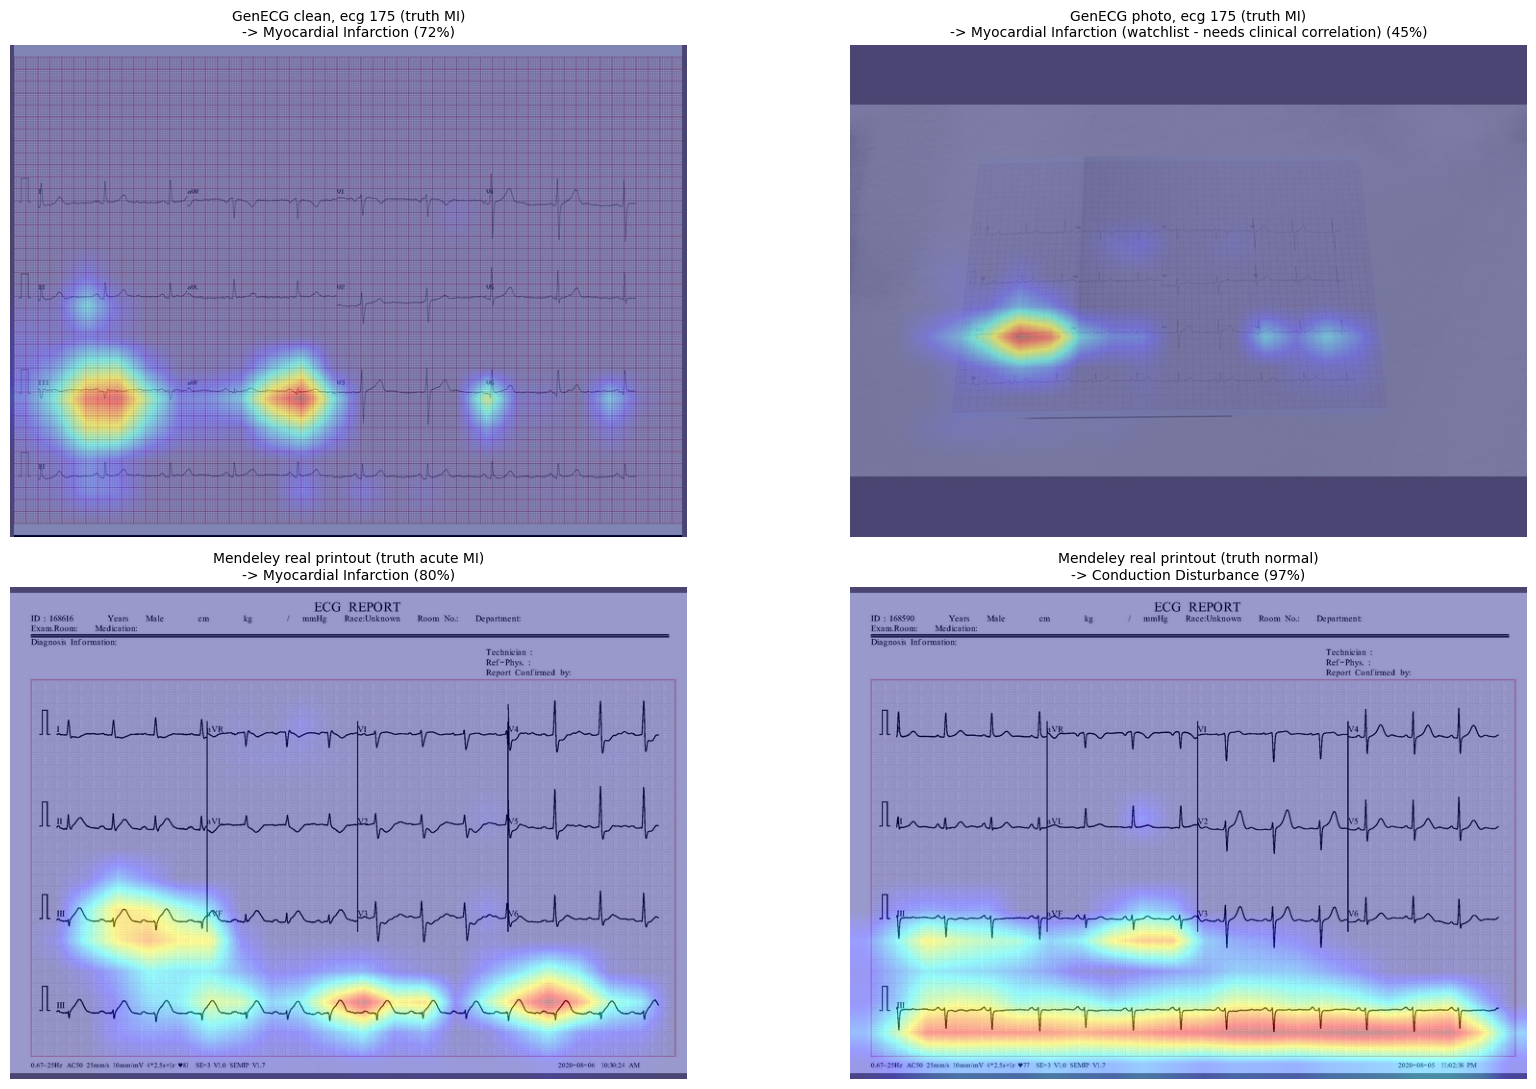


FULL JSON for the Mendeley MI example (heatmap removed):
{
  "modality": "ecg",
  "input_type": "image",
  "prediction": {
    "primary_diagnosis": "Myocardial Infarction",
    "raw_class": "MI",
    "probability": 0.8724,
    "calibrated_probability": 0.8012,
    "normality_score": 0.0028,
    "findings": [
      {
        "label": "Myocardial Infarction",
        "raw_class": "MI",
        "probability": 0.8724,
        "calibrated_probability": 0.8012,
        "threshold": 0.47,
        "risk_tier": "detected"
      },
      {
        "label": "Conduction Disturbance",
        "raw_class": "CD",
        "probability": 0.8545,
        "calibrated_probability": 0.783,
        "threshold": 0.42,
        "risk_tier": "detected"
      },
      {
        "label": "ST/T-wave Changes",
        "raw_class": "STTC",
        "probability": 0.4434,
        "calibrated_probability": 0.4589,
        "threshold": 0.37,
        "risk_tier": "detected"
      },
      {
        "label": "Ventricular

In [16]:
import sys, importlib, json, base64, io
from PIL import Image
DEP = f'{DRIVE_ROOT}/deploy'
if DEP not in sys.path: sys.path.insert(0, DEP)
import ecg_inference as E; importlib.reload(E)
WTS = f'{DEP}/weights/ecg_convnext_v3_deploy.pth'

# Mendeley images (unzip again if the session restarted)
MEND = '/content/mendeley'
if not glob.glob(f'{MEND}/*/*.jpg'):
    !unzip -q "{DRIVE_ROOT}/external/gwbz3fsgp8-2.zip" -d {MEND}
u = pd.read_csv(f'{DRIVE_ROOT}/external/unique_images.csv')
u['local'] = MEND + '/' + u.path.str.split('/', n=3).str[3]

eid = 175   # PTB-XL inferior MI from the test fold (used in the Grad-CAM check)
examples = {
    f'GenECG clean, ecg {eid} (truth MI)': f"{CACHE}/A/{SPL['A']['test'].loc[eid].rel_path[:-4]}.jpg",
    f'GenECG photo, ecg {eid} (truth MI)': f"{CACHE}/B/{SPL['B']['test'].loc[eid].rel_path[:-4]}.jpg",
    'Mendeley real printout (truth acute MI)': u[u.cls == 'mi'].local.iloc[0],
    'Mendeley real printout (truth normal)':   u[u.cls == 'normal'].local.iloc[0],
}

samples, fig = {}, plt.figure(figsize=(18, 11))
for k, (name, path) in enumerate(examples.items()):
    out = E.predict_ecg(open(path, 'rb').read(), model_path=WTS, device='cuda', gradcam=True)  # bytes, like the API
    p = out['prediction']
    print(f"\n=== {name}\n  primary: {p['primary_diagnosis']} ({p['calibrated_probability']:.1%}) | "
          f"normality {p['normality_score']:.1%} | abstain {p['abstain']} | risk {p['risk_summary']['overall_risk']}")
    print('  all classes:', {f['raw_class']: f"{f['calibrated_probability']:.2f} {f['risk_tier']}" for f in p['findings']})
    print('  positive:', out['evidence']['positive_findings'][:2])
    print('  negative[0]:', out['evidence']['negative_findings'][0])
    heat = out['explainability'].pop('heatmap_png_base64')
    Image.open(io.BytesIO(base64.b64decode(heat))).save(f'{DEP}/sample_heatmap_{k}.png')
    ax = fig.add_subplot(2, 2, k + 1); ax.imshow(Image.open(f'{DEP}/sample_heatmap_{k}.png'))
    ax.set_title(f"{name}\n-> {p['primary_diagnosis']} ({p['calibrated_probability']:.0%})", fontsize=10); ax.axis('off')
    samples[name] = out
plt.tight_layout(); plt.show()

json.dump(samples, open(f'{DEP}/sample_outputs.json', 'w'), indent=2)
print('\nFULL JSON for the Mendeley MI example (heatmap removed):')
print(json.dumps(samples['Mendeley real printout (truth acute MI)'], indent=2))

# CPU speed, as on a laptop backend without GPU
ts = []
for path in u.local.iloc[:6]:
    t = time.time(); E.predict_ecg(path, model_path=WTS, device='cpu'); ts.append(time.time() - t)
print(f'\nCPU time per image (Colab 2-core CPU): first {ts[0]:.1f}s (loads model), then {np.mean(ts[1:]):.1f}s')
!ls -lh {DEP}

In [17]:
# runs the deploy module (not the training code) on every fold-10 test image
def run_module(df, sub):
    P, prim, ab = [], [], []
    for r in df.rel_path:
        o = E.predict_ecg(f'{CACHE}/{sub}/{r[:-4]}.jpg', model_path=WTS, device='cuda')
        d = {f['raw_class']: f['calibrated_probability'] for f in o['prediction']['findings']}
        P.append([d[c] for c in SUPER]); prim.append(o['prediction']['raw_class']); ab.append(o['prediction']['abstain'])
    return np.array(P), np.array(prim), np.array(ab)

rows = []
for sub, ref in [('A', 0.9310), ('B', 0.9173)]:
    df = SPL[sub]['test']; y = df[SUPER].values; t = time.time()
    P, prim, ab = run_module(df, sub)
    auc = np.mean([roc_auc_score(y[:, i], P[:, i]) for i in range(len(SUPER))])
    # is the primary diagnosis one of the true labels? (only for cases not referred)
    hit = np.array([p in SUPER and y[i, SUPER.index(p)] == 1 for i, p in enumerate(prim)])
    rows.append({'test_set': f'{sub}_test', 'n': len(df), 'module_macro_AUROC': round(auc, 4), 'notebook_AUROC': ref,
                 'referred (abstain)': f'{ab.mean():.1%}',
                 'primary correct, not referred': f'{hit[~ab].mean():.1%}',
                 'primary correct, all': f'{hit.mean():.1%}', 'seconds': round(time.time() - t)})
    print(sub, 'primary diagnosis counts:', pd.Series(prim).value_counts().to_dict())
chk = pd.DataFrame(rows); chk.to_csv(f'{DEP}/module_check.csv', index=False)
print(chk.to_string(index=False))

A primary diagnosis counts: {'NORM': 759, 'STTC': 443, 'MI': 405, 'CD': 403, 'HYP': 148}
B primary diagnosis counts: {'NORM': 809, 'STTC': 411, 'MI': 405, 'CD': 397, 'HYP': 134}
test_set    n  module_macro_AUROC  notebook_AUROC referred (abstain) primary correct, not referred primary correct, all  seconds
  A_test 2158              0.9310          0.9310              14.6%                         87.1%                79.6%       89
  B_test 2156              0.9173          0.9173              12.4%                         83.8%                78.5%       83


In [15]:
MOD = f'{DEP}/ecg_inference.py'
src = open(MOD).read()
old = '''        if not norm_positive:
            abstain, abstain_reason = True, "No condition reaches its threshold and normality is low."'''
new = '''        if norm_positive:
            abstain, abstain_reason = True, (f"Borderline: model leans normal ({normality_score:.0%}) but cannot "
                                             f"rule out {primary['label']} ({primary['calibrated_probability']:.0%}).")
        else:
            abstain, abstain_reason = True, "No condition reaches its threshold and normality is low."'''
assert src.count(old) == 1, 'patch target not found'
open(MOD, 'w').write(src.replace(old, new))
!rm -rf {DEP}/__pycache__
importlib.reload(E)
print('patched; borderline rule present:', 'leans normal' in open(MOD).read())

patched; borderline rule present: True


In [18]:
rows = []
for g in ['normal', 'mi', 'history_mi', 'abnormal']:
    outs = [E.predict_ecg(p, model_path=WTS, device='cuda')['prediction'] for p in u[u.cls == g].local]
    det = lambda name: f"{np.mean([name in o['detected_conditions'] for o in outs]):.0%}"
    rows.append({'true_group': g, 'n': len(outs),
                 'primary=Normal': f"{np.mean([o['raw_class'] == 'NORM' for o in outs]):.0%}",
                 'primary=MI': f"{np.mean([o['raw_class'] == 'MI' for o in outs]):.0%}",
                 'MI det': det('Myocardial Infarction'), 'STTC det': det('ST/T-wave Changes'),
                 'CD det': det('Conduction Disturbance'), 'HYP det': det('Ventricular Hypertrophy'),
                 'referred': f"{np.mean([o['abstain'] for o in outs]):.0%}"})
men = pd.DataFrame(rows); men.to_csv(f'{DEP}/mendeley_module_behaviour.csv', index=False)
print(men.to_string(index=False))

true_group   n primary=Normal primary=MI MI det STTC det CD det HYP det referred
    normal 142            54%        19%    14%       9%    11%      2%      23%
        mi  30             0%        83%    90%      17%    47%     20%       0%
history_mi  86             0%        81%    92%      28%    24%      8%       1%
  abnormal 233            14%        23%    35%      40%    33%     16%      19%
